In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CLEAN_DATA_PATH = "../data/processed/dblp_clean_2015_2025.parquet"
STATS_OUT_DIR = "../data/results"
FIGURES_DIR = "../figures"

os.makedirs(STATS_OUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_parquet(CLEAN_DATA_PATH)
print(f"dataset: {len(df):,} publikasi dari {df['venue_code'].nunique():,} konferensi unik")
df.head(3)

dataset: 1,997,145 publikasi dari 4,372 konferensi unik


,paper_key,title,year,venue_code,venue_name,authors
0,conf/dac/RoquetSRTSK24,Cross-Layer Reliability Evaluation and Efficie...,2024,dac,DAC,"[Lucas Roquet, Fernando Fernandes dos Santos, ..."
1,conf/dac/LiuZWCYHYJ22,SATO: spiking neural network acceleration via ...,2022,dac,DAC,"[Fangxin Liu, Wenbo Zhao 0005, Zongwu Wang, Yo..."
2,conf/dac/AhnYLHKP20,Hawkware: Network Intrusion Detection based on...,2020,dac,DAC,"[Sunwoo Ahn, Hayoon Yi, Younghan Lee 0001, Who..."


In [9]:
# jumlah publikasi dan rata-rata penulis per paper untuk setiap venue
venue_pubs = (
    df.groupby("venue_code")
    .agg(
        total_publications=("paper_key", "count"),
        sample_venue_name=("venue_name", "first"),
        avg_authors_per_paper=("authors", lambda s: s.str.len().mean())
    )
    .reset_index()
)

# jumlah author unik per venue
df_exploded = df[["venue_code", "authors"]].explode("authors")
venue_unique_authors = (
    df_exploded.groupby("venue_code")["authors"]
    .nunique()
    .reset_index(name="unique_authors")
)

venue_stats = pd.merge(venue_pubs, venue_unique_authors, on="venue_code")
venue_stats["pubs_per_unique_author"] = (
    venue_stats["total_publications"] / venue_stats["unique_authors"]
).round(2)
venue_stats["avg_authors_per_paper"] = venue_stats["avg_authors_per_paper"].round(2)

# top 10 berdasarkan jumlah publikasi
top10_pubs = (
    venue_stats.sort_values("total_publications", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top10_pubs["rank_pubs"] = top10_pubs.index + 1

# top 10 berdasarkan jumlah author unik
top10_authors = (
    venue_stats.sort_values("unique_authors", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top10_authors["rank_authors"] = top10_authors.index + 1

print("top 10 konferensi berdasarkan jumlah publikasi")
display(top10_pubs[["rank_pubs", "venue_code", "total_publications", "unique_authors", "avg_authors_per_paper", "sample_venue_name"]])

print("top 10 konferensi berdasarkan jumlah author unik")
display(top10_authors[["rank_authors", "venue_code", "unique_authors", "total_publications", "avg_authors_per_paper", "sample_venue_name"]])

top 10 konferensi berdasarkan jumlah publikasi


,rank_pubs,venue_code,total_publications,unique_authors,avg_authors_per_paper,sample_venue_name
0,1,nips,25455,57798,4.95,NIPS
1,2,cvpr,22751,47657,5.23,CVPR
2,3,icassp,21606,42057,4.10,ICASSP
3,4,hci,19912,37884,3.47,HCI (6)
4,5,igarss,19685,35229,4.72,IGARSS
5,6,aaai,19274,46431,4.42,AAAI
6,7,chi,14832,29904,4.48,CHI
7,8,emnlp,14813,33953,4.95,EMNLP (Findings)
8,9,embc,14676,39318,4.93,EMBC
9,10,icc,14329,26624,3.99,ICC


top 10 konferensi berdasarkan jumlah author unik


,rank_authors,venue_code,unique_authors,total_publications,avg_authors_per_paper,sample_venue_name
0,1,nips,57798,25455,4.95,NIPS
1,2,cvpr,47657,22751,5.23,CVPR
2,3,aaai,46431,19274,4.42,AAAI
3,4,icassp,42057,21606,4.10,ICASSP
4,5,embc,39318,14676,4.93,EMBC
5,6,hci,37884,19912,3.47,HCI (6)
6,7,igarss,35229,19685,4.72,IGARSS
7,8,emnlp,33953,14813,4.95,EMNLP (Findings)
8,9,icml,31893,13778,4.52,ICML
9,10,iros,31248,12851,4.45,IROS


In [10]:
# peringkat global seluruh konferensi untuk kedua metrik
venue_stats["rank_pubs"] = venue_stats["total_publications"].rank(ascending=False, method="min").astype(int)
venue_stats["rank_authors"] = venue_stats["unique_authors"].rank(ascending=False, method="min").astype(int)
venue_stats["rank_diff (pubs - authors)"] = venue_stats["rank_pubs"] - venue_stats["rank_authors"]

# union dari top 10 publikasi dan top 10 author unik
union_top_venues = set(top10_pubs["venue_code"]).union(set(top10_authors["venue_code"]))
df_rank_comparison = (
    venue_stats[venue_stats["venue_code"].isin(union_top_venues)]
    .sort_values("rank_pubs")
    .reset_index(drop=True)
)

top10_pubs.to_csv(f"{STATS_OUT_DIR}/task2_top10_publications.csv", index=False)
top10_authors.to_csv(f"{STATS_OUT_DIR}/task2_top10_unique_authors.csv", index=False)
df_rank_comparison.to_csv(f"{STATS_OUT_DIR}/task2_ranking_comparison.csv", index=False)

display(df_rank_comparison[[
    "venue_code", "rank_pubs", "total_publications", 
    "rank_authors", "unique_authors", "rank_diff (pubs - authors)", "avg_authors_per_paper"
]])

,venue_code,rank_pubs,total_publications,rank_authors,unique_authors,rank_diff (pubs - authors),avg_authors_per_paper
0,nips,1,25455,1,57798,0,4.95
1,cvpr,2,22751,2,47657,0,5.23
2,icassp,3,21606,4,42057,-1,4.10
3,hci,4,19912,6,37884,-2,3.47
4,igarss,5,19685,7,35229,-2,4.72
5,aaai,6,19274,3,46431,3,4.42
6,chi,7,14832,12,29904,-5,4.48
7,emnlp,8,14813,8,33953,0,4.95
8,embc,9,14676,5,39318,4,4.93
9,icc,10,14329,19,26624,-9,3.99


In [11]:
# tren keseluruhan publikasi dan author unik per tahun
yearly_overall = (
    df.groupby("year")
    .agg(
        total_publications=("paper_key", "count"),
        active_venues=("venue_code", "nunique")
    )
    .reset_index()
)
yearly_overall["yoy_growth (%)"] = (yearly_overall["total_publications"].pct_change() * 100).round(2)

# tren tahunan khusus untuk top 6 konferensi berdasarkan total publikasi
top6_codes = top10_pubs["venue_code"].head(6).tolist()
yearly_top6 = (
    df[df["venue_code"].isin(top6_codes)]
    .groupby(["year", "venue_code"])["paper_key"]
    .count()
    .unstack(fill_value=0)
)

yearly_overall.to_csv(f"{STATS_OUT_DIR}/task2_yearly_overall_trend.csv", index=False)
yearly_top6.to_csv(f"{STATS_OUT_DIR}/task2_yearly_top6_trend.csv")

print("tren publikasi konferensi keseluruhan (2015–2025)")
display(yearly_overall)

print("tren tahunan khusus untuk top 6 konferensi berdasarkan total publikasi")
display(yearly_top6)

tren publikasi konferensi keseluruhan (2015–2025)


,year,total_publications,active_venues,yoy_growth (%)
0,2015,160800,1975,NaN
1,2016,161650,2016,0.53
2,2017,167767,2066,3.78
3,2018,176309,2158,5.09
4,2019,188436,2241,6.88
5,2020,171772,2045,-8.84
6,2021,178166,2217,3.72
7,2022,178074,2275,-0.05
8,2023,201387,2356,13.09
9,2024,213301,2273,5.92


tren tahunan khusus untuk top 6 konferensi berdasarkan total publikasi


venue_code,aaai,cvpr,hci,icassp,igarss,nips
year,,,,,,
2015,790,733,1713,1198,1353,440
2016,812,836,1470,1322,1905,594
2017,930,1064,1404,1321,1569,677
2018,1218,1326,1365,1395,2208,1009
2019,1392,1882,1582,1735,2273,1518
2020,1905,1984,2153,1863,1641,1949
2021,2061,2174,1834,1723,2152,2562
2022,1700,2627,2025,1864,1936,2849
2023,2076,3051,2238,2920,2059,3540


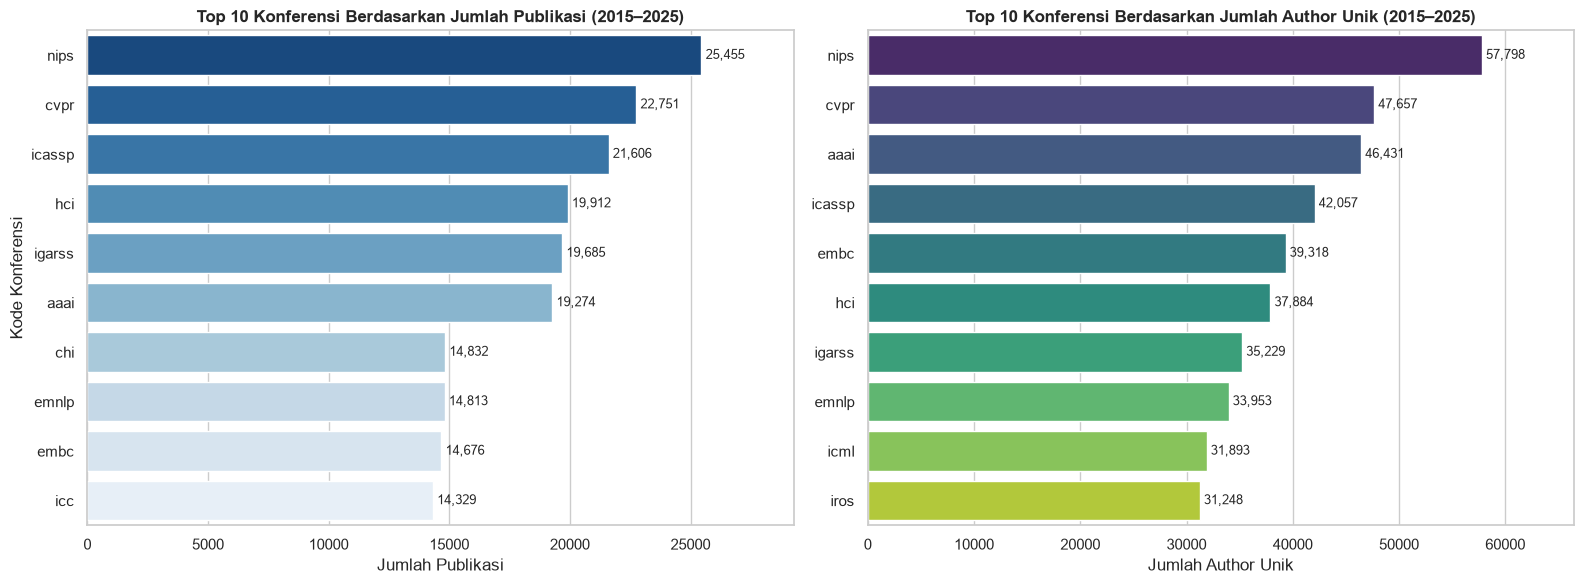

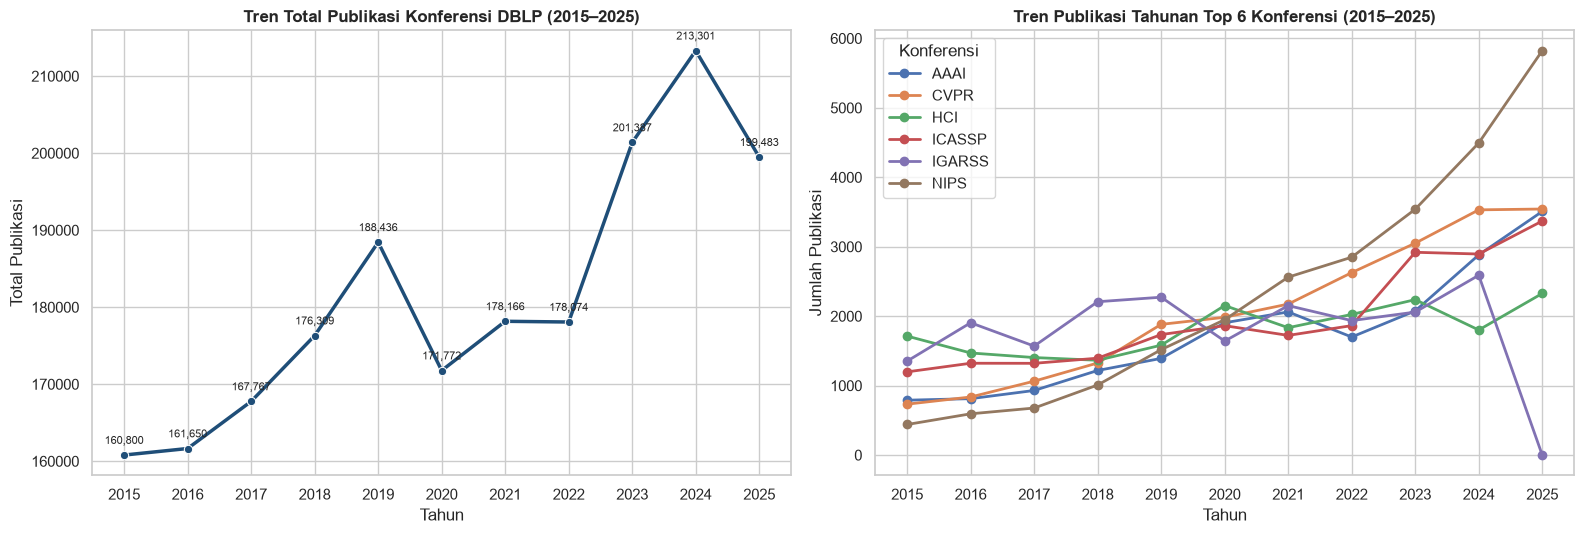

In [12]:
sns.set_theme(style="whitegrid")

# plot 1: perbandingan top 10 publikasi vs top 10 author unik
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top10_pubs, y="venue_code", x="total_publications", palette="Blues_r", hue="venue_code", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Konferensi Berdasarkan Jumlah Publikasi (2015–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Publikasi")
axes[0].set_ylabel("Kode Konferensi")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="{:,.0f}", fontsize=9, padding=3)
axes[0].set_xlim(0, top10_pubs["total_publications"].max() * 1.15)

sns.barplot(data=top10_authors, y="venue_code", x="unique_authors", palette="viridis", hue="venue_code", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Konferensi Berdasarkan Jumlah Author Unik (2015–2025)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Author Unik")
axes[1].set_ylabel("")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="{:,.0f}", fontsize=9, padding=3)
axes[1].set_xlim(0, top10_authors["unique_authors"].max() * 1.15)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task2_top10_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# plot 2: tren keseluruhan publikasi dan tren tahunan top 6 konferensi
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.lineplot(data=yearly_overall, x="year", y="total_publications", marker="o", linewidth=2.5, color="#1f4e78", ax=axes[0])
axes[0].set_title("Tren Total Publikasi Konferensi DBLP (2015–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Total Publikasi")
axes[0].set_xticks(range(2015, 2026))
for _, row in yearly_overall.iterrows():
    axes[0].annotate(f"{int(row['total_publications']):,}", (row["year"], row["total_publications"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

for col in yearly_top6.columns:
    axes[1].plot(yearly_top6.index, yearly_top6[col], marker="o", linewidth=2, label=col.upper())
axes[1].set_title("Tren Publikasi Tahunan Top 6 Konferensi (2015–2025)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Jumlah Publikasi")
axes[1].set_xticks(range(2015, 2026))
axes[1].legend(title="Konferensi", loc="upper left")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task2_publication_trends.png", dpi=300, bbox_inches="tight")
plt.show()